# NB07 — Pooled Embeddings + Few-Shot Split

**Project:** RanSMAP — real-time ransomware detection  
**Input:** `features/text_sequences.npy` — (190, 300, 384) MiniLM embeddings (one 384-d vector per 0.1s window)  
**Outputs:**
- `features/pooled_embeddings.npy` — (190, 384) mean-pooled per-execution vectors  
- `features/pooled_embeddings_attn.npy` — (190, 384) norm-weighted attention-pooled  
- `features/fewshot_split.npz` — episodic train/val/test split for partner's MAML  

**Why pooling:** The GAN generates one 384-d vector per synthetic execution; the partner's MAML consumes one 384-d vector per execution. Mean/attention-pool collapses the 300-window sequence into that single vector without losing class structure.

**Why this notebook exists before the GAN:** the pooled embedding space is the GAN's output space and the MAML's input space — defining and validating it locally (190 executions) before migrating to Canada Alliance.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import StratifiedShuffleSplit
import umap

FEATURES_DIR = Path('features')
SEED = 42
np.random.seed(SEED)

# 3-way label map (same as NB03/NB05)
LABEL_3WAY = {
    'WannaCry': 'Ransomware', 'Ryuk': 'Ransomware', 'REvil': 'Ransomware',
    'LockBit': 'Ransomware', 'Darkside': 'Ransomware', 'Conti': 'Ransomware',
    'AESCrypt': 'Legit-Encryption', 'SDelete': 'Legit-Encryption', 'Zip': 'Legit-Encryption',
    'Firefox': 'Benign', 'Office': 'Benign', 'Idle': 'Benign',
}
VARIANT_CLASSES = [f'Conti_0{i}' for i in range(1, 8)]

print('Config ready.')


/home/arshad/Claude/Projects/Directed Study/Ransomware/ransmap_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Config ready.


## 1. Load embeddings + metadata

In [2]:
meta_df   = pd.read_csv(FEATURES_DIR / 'metadata.csv')
text_seqs = np.load(FEATURES_DIR / 'text_sequences.npy')  # (190, 300, 384)
labels    = meta_df['label'].values
groups    = meta_df['group'].values

# 3-way labels (variants get their own fine-grained label; kept separate)
labels_3way = np.array([
    LABEL_3WAY.get(l, l) for l in labels   # variants not in map → kept as-is
])

orig_mask = groups == 'original'
var_mask  = groups == 'variant'

print(f'text_seqs shape : {text_seqs.shape}')
print(f'Originals       : {orig_mask.sum()}  ({np.unique(labels[orig_mask]).tolist()})')
print(f'Variants        : {var_mask.sum()}   ({np.unique(labels[var_mask]).tolist()})')
print(f'3-way dist (originals):')
for cls in ['Ransomware', 'Legit-Encryption', 'Benign']:
    n = ((labels_3way == cls) & orig_mask).sum()
    print(f'  {cls}: {n}')


text_seqs shape : (190, 300, 384)
Originals       : 120  (['AESCrypt', 'Conti', 'Darkside', 'Firefox', 'Idle', 'LockBit', 'Office', 'REvil', 'Ryuk', 'SDelete', 'WannaCry', 'Zip'])
Variants        : 70   (['Conti_01', 'Conti_02', 'Conti_03', 'Conti_04', 'Conti_05', 'Conti_06', 'Conti_07'])
3-way dist (originals):
  Ransomware: 60
  Legit-Encryption: 30
  Benign: 30


## 2. Pool sequences → one 384-d vector per execution

**Mean pool:** uniform average over all 300 windows. Simple, fast, lossless of class-level statistics.

**Attention pool:** weight each window by the L2 norm of its embedding — higher-norm windows (more active / more signal) get more weight. No learned parameters; a proxy for informativeness.

In [3]:
# Mean pool: (190, 300, 384) → (190, 384)
pooled_mean = text_seqs.mean(axis=1)

# Attention pool: weight by per-window L2 norm
norms   = np.linalg.norm(text_seqs, axis=-1, keepdims=True)  # (190, 300, 1)
# softmax over the 300-window axis
norms_e = np.exp(norms - norms.max(axis=1, keepdims=True))   # numerically stable
weights = norms_e / norms_e.sum(axis=1, keepdims=True)       # (190, 300, 1)
pooled_attn = (text_seqs * weights).sum(axis=1)              # (190, 384)

print(f'Mean-pooled  shape : {pooled_mean.shape}  | L2 norm mean: {np.linalg.norm(pooled_mean, axis=-1).mean():.3f}')
print(f'Attn-pooled  shape : {pooled_attn.shape}  | L2 norm mean: {np.linalg.norm(pooled_attn, axis=-1).mean():.3f}')

# Sanity: correlation between the two
cos_sim = (pooled_mean * pooled_attn).sum(-1) / (
    np.linalg.norm(pooled_mean, axis=-1) * np.linalg.norm(pooled_attn, axis=-1))
print(f'Mean cosine similarity between pooling methods: {cos_sim.mean():.4f} (close to 1 = nearly identical)')


Mean-pooled  shape : (190, 384)  | L2 norm mean: 0.856
Attn-pooled  shape : (190, 384)  | L2 norm mean: 0.856
Mean cosine similarity between pooling methods: 1.0000 (close to 1 = nearly identical)


## 3. UMAP — verify 3-way class structure survives pooling

If the pooled 384-d space separates the 3 macro-classes and clusters variants near Conti, pooling is lossless for the downstream tasks.

/home/arshad/Claude/Projects/Directed Study/Ransomware/ransmap_env/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


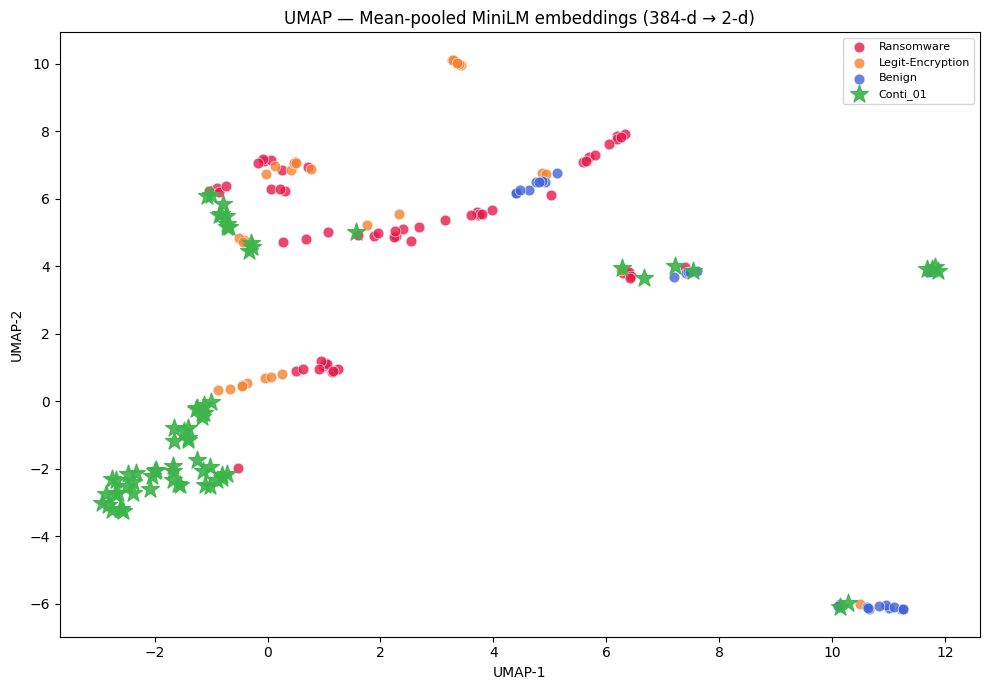

Saved → features/pooled_umap.png


In [4]:
reducer = umap.UMAP(n_components=2, n_neighbors=10, min_dist=0.1,
                    metric='cosine', random_state=SEED)
emb2d = reducer.fit_transform(pooled_mean)  # fit on mean-pooled

COLOR = {'Ransomware': '#e6194b', 'Legit-Encryption': '#f58231',
         'Benign': '#4363d8', **{v: '#3cb44b' for v in VARIANT_CLASSES}}
MARKER = {**{v: '*' for v in VARIANT_CLASSES}}

fig, ax = plt.subplots(figsize=(10, 7))
for cls in ['Ransomware', 'Legit-Encryption', 'Benign']:
    m = (labels_3way == cls) & orig_mask
    ax.scatter(emb2d[m, 0], emb2d[m, 1], c=COLOR[cls], label=cls,
               s=60, alpha=0.8, edgecolors='white', linewidths=0.5)
for v in VARIANT_CLASSES:
    m = labels == v
    if m.sum():
        ax.scatter(emb2d[m, 0], emb2d[m, 1], c=COLOR[v], marker='*',
                   s=180, label=v if v == 'Conti_01' else '_', alpha=0.9)

ax.set_title('UMAP — Mean-pooled MiniLM embeddings (384-d → 2-d)')
ax.legend(loc='best', fontsize=8)
ax.set_xlabel('UMAP-1'); ax.set_ylabel('UMAP-2')
plt.tight_layout()
plt.savefig(FEATURES_DIR / 'pooled_umap.png', dpi=150)
plt.show()
print('Saved → features/pooled_umap.png')


## 4. Episodic few-shot split

**Split design:**
- `train` pool (80% of each 3-way class in originals) — episodes drawn from here during MAML training
- `val` pool (20% of originals) — same distribution, used for MAML validation episodes
- `test` pool — all 70 Conti variants (always held out; these are the zero-day proxies)

**Format saved in `fewshot_split.npz`:**
- `train_idx`, `val_idx`, `test_idx` — integer indices into `pooled_embeddings.npy`
- `labels_3way`, `labels_fine` — 3-way and 12-class string labels for all 190 executions
- `class_names_3way` — the 3 class names in order
- `variant_names` — the 7 variant names

The partner's MAML samples N-way K-shot episodes from `train_idx` during training, evaluates on `val_idx`, and tests zero-day generalization using `test_idx`.

In [5]:
# Indices of the 120 originals
orig_idx  = np.where(orig_mask)[0]           # (120,)
orig_3way = labels_3way[orig_mask]           # 3-way labels for originals only

# Stratified 80/20 split of the 120 originals
sss = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
tr_local, val_local = next(sss.split(orig_idx, orig_3way))

train_idx = orig_idx[tr_local]   # indices into full 190-array
val_idx   = orig_idx[val_local]
test_idx  = np.where(var_mask)[0]            # all 70 variants

print(f'Train pool : {len(train_idx)} executions')
for cls in ['Ransomware', 'Legit-Encryption', 'Benign']:
    print(f'  {cls}: {(labels_3way[train_idx] == cls).sum()}')
print(f'Val pool   : {len(val_idx)} executions')
for cls in ['Ransomware', 'Legit-Encryption', 'Benign']:
    print(f'  {cls}: {(labels_3way[val_idx] == cls).sum()}')
print(f'Test pool  : {len(test_idx)} executions (all 7 Conti variants)')
for v in VARIANT_CLASSES:
    print(f'  {v}: {(labels[test_idx] == v).sum()}')


Train pool : 96 executions
  Ransomware: 48
  Legit-Encryption: 24
  Benign: 24
Val pool   : 24 executions
  Ransomware: 12
  Legit-Encryption: 6
  Benign: 6
Test pool  : 70 executions (all 7 Conti variants)
  Conti_01: 10
  Conti_02: 10
  Conti_03: 10
  Conti_04: 10
  Conti_05: 10
  Conti_06: 10
  Conti_07: 10


## 5. Save all outputs

In [6]:
# Pooled embeddings
np.save(FEATURES_DIR / 'pooled_embeddings.npy',      pooled_mean.astype(np.float32))
np.save(FEATURES_DIR / 'pooled_embeddings_attn.npy', pooled_attn.astype(np.float32))

# Few-shot split
np.savez(
    FEATURES_DIR / 'fewshot_split.npz',
    train_idx      = train_idx,
    val_idx        = val_idx,
    test_idx       = test_idx,
    labels_3way    = labels_3way,
    labels_fine    = labels,
    class_names_3way = np.array(['Ransomware', 'Legit-Encryption', 'Benign']),
    variant_names  = np.array(VARIANT_CLASSES),
)

print('Saved:')
print(f'  features/pooled_embeddings.npy      {pooled_mean.shape}  float32')
print(f'  features/pooled_embeddings_attn.npy {pooled_attn.shape}  float32')
print(f'  features/fewshot_split.npz')
print(f'    train_idx: {train_idx.shape}  val_idx: {val_idx.shape}  test_idx: {test_idx.shape}')


Saved:
  features/pooled_embeddings.npy      (190, 384)  float32
  features/pooled_embeddings_attn.npy (190, 384)  float32
  features/fewshot_split.npz
    train_idx: (96,)  val_idx: (24,)  test_idx: (70,)


## 6. Partner usage — how to consume these files

```python
import numpy as np

# Load pooled embeddings (one 384-d vector per execution)
X = np.load('features/pooled_embeddings.npy')   # (190, 384)

# Load split
split = np.load('features/fewshot_split.npz', allow_pickle=True)
train_idx       = split['train_idx']        # 96 original executions for episodic training
val_idx         = split['val_idx']          # 24 original executions for validation
test_idx        = split['test_idx']         # 70 Conti variant executions (zero-day test)
labels_3way     = split['labels_3way']      # string labels: 'Ransomware', 'Legit-Encryption', 'Benign'
labels_fine     = split['labels_fine']      # fine-grained: 'WannaCry', 'AESCrypt', etc.

X_train = X[train_idx]   # (96, 384) — sample episodes from here
y_train = labels_3way[train_idx]

X_test  = X[test_idx]    # (70, 384) — zero-day generalization test
y_test  = labels_fine[test_idx]   # Conti_01 .. Conti_07
```

**GAN note:** the GAN (NB08, to be built on Canada Alliance) will generate new 384-d vectors with the same distribution as `X_train`, emphasising the Legit-Encryption class. Generated vectors are appended to `X_train` before episodic MAML training.

In [7]:
print('=' * 55)
print('NB07 — POOLED EMBEDDINGS + FEW-SHOT SPLIT — SUMMARY')
print('=' * 55)
print(f'Source sequences : text_sequences.npy  {text_seqs.shape}')
print(f'Pooled (mean)    : pooled_embeddings.npy  {pooled_mean.shape}')
print(f'Pooled (attn)    : pooled_embeddings_attn.npy  {pooled_attn.shape}')
print(f'Cosine sim (mean vs attn): {cos_sim.mean():.4f}')
print()
print('Few-shot split (fewshot_split.npz):')
print(f'  Train pool : {len(train_idx):3d} executions (80% of originals, stratified)')
print(f'  Val pool   : {len(val_idx):3d} executions (20% of originals, stratified)')
print(f'  Test pool  : {len(test_idx):3d} executions (all 7 Conti variants — zero-day)')
print()
print('UMAP → features/pooled_umap.png')
print()
print('Next: GAN (NB08, Canada Alliance) — conditional GAN over 3-way classes')
print('      generating 384-d vectors; emphasis on Legit-Encryption augmentation.')


NB07 — POOLED EMBEDDINGS + FEW-SHOT SPLIT — SUMMARY
Source sequences : text_sequences.npy  (190, 300, 384)
Pooled (mean)    : pooled_embeddings.npy  (190, 384)
Pooled (attn)    : pooled_embeddings_attn.npy  (190, 384)
Cosine sim (mean vs attn): 1.0000

Few-shot split (fewshot_split.npz):
  Train pool :  96 executions (80% of originals, stratified)
  Val pool   :  24 executions (20% of originals, stratified)
  Test pool  :  70 executions (all 7 Conti variants — zero-day)

UMAP → features/pooled_umap.png

Next: GAN (NB08, Canada Alliance) — conditional GAN over 3-way classes
      generating 384-d vectors; emphasis on Legit-Encryption augmentation.
